# Imports & Paths

In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_curve, auc, precision_recall_curve,average_precision_score, f1_score, precision_score, recall_score
import matplotlib.pyplot as plt
import ast
from pathlib import Path

BASE_DIR = Path(__file__).resolve().parent if "__file__" in dir() else Path.cwd()
DATA_DIR = BASE_DIR / "data"

# load the input data

## load OneHotEncoding as y

In [4]:
OHE_train = pd.read_csv(DATA_DIR / "OHE_train_dataset_All_Food.csv", sep=';', header=0, index_col=0)
OHE_test = pd.read_csv(DATA_DIR / "OHE_test_dataset_All_Food.csv", sep=';', header=0, index_col=0)

y_train = np.array([
    np.array(ast.literal_eval(f), dtype=int)
    for f in OHE_train['OneHotEncoding']
])
y_test = np.array([
    np.array(ast.literal_eval(f), dtype=int)
    for f in OHE_test['OneHotEncoding']
])

## load Mordred as x

In [5]:
X_train_index = pd.read_csv(DATA_DIR / 'X_train_features_Mordred.csv', sep=',')
X_test_index = pd.read_csv(DATA_DIR / 'X_test_features_Mordred.csv', sep=',')
X_test = np.delete(X_test_index, 0, 1)
X_train = np.delete(X_train_index, 0, 1)

# ML models

## optimized RandomForest

In [6]:
from sklearn.ensemble import RandomForestClassifier

classifier = "RF"
number_e = 1100
min_samples_l = 3
min_samples_s = 2

RFCLassifier = RandomForestClassifier(
    random_state=42,
    n_estimators=number_e,
    min_samples_leaf=min_samples_l,
    min_samples_split=min_samples_s
)
RFCLassifier.fit(X_train, y_train)
y_scores_RF = RFCLassifier.predict_proba(X_test)
y_pred_RF = RFCLassifier.predict(X_test)

## optimized CatBoost

In [7]:
from catboost import CatBoostClassifier
from sklearn.multiclass import OneVsRestClassifier

classifier = "Cat"
learning = 0.01
dep = 6

Cat = OneVsRestClassifier(CatBoostClassifier(
    n_estimators=1000,
    depth=dep,
    learning_rate=learning,
    loss_function='Logloss',
    random_seed=42,
    verbose=False
))
Cat.fit(X_train, y_train)
y_scores_Cat = Cat.predict_proba(X_test)
y_pred_Cat = Cat.predict(X_test)

0:	learn: 0.6733368	total: 63ms	remaining: 1m 2s
1:	learn: 0.6536847	total: 75.4ms	remaining: 37.6s
2:	learn: 0.6339991	total: 87.5ms	remaining: 29.1s
3:	learn: 0.6145499	total: 103ms	remaining: 25.7s
4:	learn: 0.5957341	total: 117ms	remaining: 23.3s
5:	learn: 0.5783536	total: 130ms	remaining: 21.6s
6:	learn: 0.5618304	total: 142ms	remaining: 20.2s
7:	learn: 0.5456397	total: 156ms	remaining: 19.4s
8:	learn: 0.5300652	total: 156ms	remaining: 19.4s
9:	learn: 0.5141652	total: 172ms	remaining: 19s
10:	learn: 0.4985919	total: 184ms	remaining: 18.2s
11:	learn: 0.4846345	total: 197ms	remaining: 17.7s
12:	learn: 0.4713316	total: 208ms	remaining: 17.1s
13:	learn: 0.4568855	total: 222ms	remaining: 16.8s
14:	learn: 0.4440629	total: 237ms	remaining: 16.7s
15:	learn: 0.4314706	total: 249ms	remaining: 16.3s
16:	learn: 0.4195934	total: 266ms	remaining: 16.3s
17:	learn: 0.4083243	total: 266ms	remaining: 16.3s
18:	learn: 0.3975210	total: 277ms	remaining: 16s
19:	learn: 0.3863451	total: 289ms	remaining:

# ROC and PR-curve

RandomForest ROC AUC:       0.9018
RandomForest PR AUC:        0.4389
RandomForest avg_precision: 0.4391
CatBoost ROC AUC:       0.9007
CatBoost PR AUC:        0.4521
CatBoost avg_precision: 0.4523


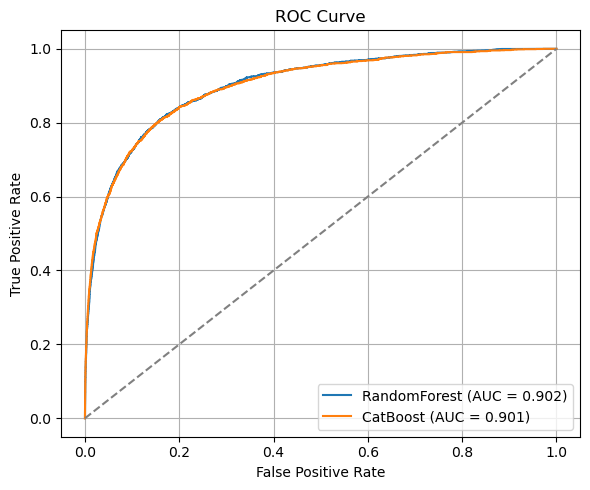

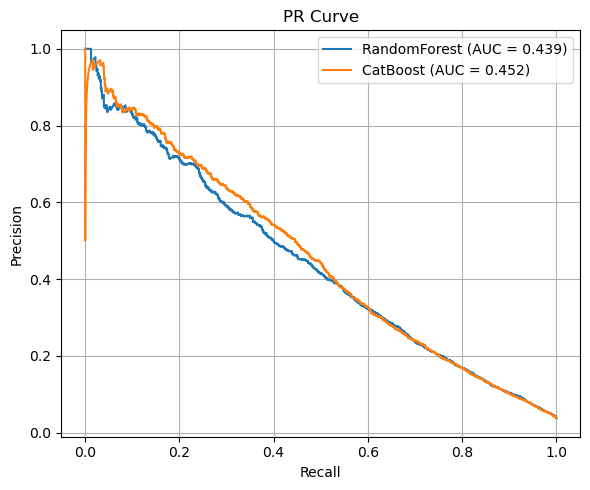

In [13]:
lists = pd.read_csv(DATA_DIR / 'Total_dataset_All_Food.csv', sep=';', header=0)["Labels"].apply(ast.literal_eval)
unique_items = list(set(item for sublist in lists for item in sublist))

OHE = pd.DataFrame(
    OHE_test["OneHotEncoding"].apply(ast.literal_eval).tolist(),
    index=OHE_test["SMILES"],
    columns=unique_items
)
OHE_num = OHE.to_numpy().flatten()

model_preds = {
    "RandomForest": np.transpose(np.array(RFCLassifier.predict_proba(X_test))[:, :, 1]).flatten(),
    "CatBoost": Cat.predict_proba(X_test).flatten(),
}
labels = list(model_preds.keys())

fpr_RF, tpr_RF, roc_auc_RF, avg_precision_RF_micro, PR_auc_RF, precision_RF, recall_RF = []

plt.figure(figsize=(6, 5))
for i, (label, results) in enumerate(model_preds.items()):
    fprRFC, tprRFC, _ = roc_curve(OHE_num, results)
    fpr_RF.append(fprRFC)
    tpr_RF.append(tprRFC)
    roc_auc_RF.append(auc(fprRFC, tprRFC))

    precisionRFC, recallRFC, _ = precision_recall_curve(OHE_num, results)
    precision_RF.append(precisionRFC)
    recall_RF.append(recallRFC)

    avg_precision_RF_micro.append(average_precision_score(OHE_num, results, average="micro"))
    PR_auc_RF.append(auc(recall_RF[i], precision_RF[i]))

    print(f'{label} ROC AUC:       {roc_auc_RF[i]:.4f}')
    print(f'{label} PR AUC:        {PR_auc_RF[i]:.4f}')
    print(f'{label} avg_precision: {avg_precision_RF_micro[i]:.4f}')

    plt.plot(fpr_RF[i], tpr_RF[i], label=f'{label} (AUC = {roc_auc_RF[i]:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.grid()
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
for i, label in enumerate(labels):
    plt.plot(recall_RF[i], precision_RF[i], label=f'{label} (AUC = {PR_auc_RF[i]:.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR Curve')
plt.legend(loc="upper right")
plt.grid()
plt.tight_layout()
plt.show()


# Classification metrics summary

In [17]:
model_bin_preds = {
    "RandomForest": y_pred_RF,
    "CatBoost": y_pred_Cat,
}
average_type = "macro"
print(f"{'Model':<15} {'F1':<14} {'Avg Score (AP)':<18} {'Precision':<20} {'Recall'}")
print("-" * 82)

metrics_rows = []
for label, y_pred in model_bin_preds.items():
    y_score_flat = model_preds[label]

    f1 = f1_score(y_test.flatten(), y_pred.flatten(), average=average_type, zero_division=0)
    avg_score = average_precision_score(OHE_num, y_score_flat, average=average_type)
    precision = precision_score(y_test.flatten(), y_pred.flatten(), average=average_type, zero_division=0)
    recall = recall_score(y_test.flatten(), y_pred.flatten(), average=average_type, zero_division=0)

    metrics_rows.append({
        "Model": label,
        f"F1 ({average_type})": round(f1, 4),
        "Avg Score (AP)":  round(avg_score, 4),
        f"Precision ({average_type})": round(precision, 4),
        f"Recall ({average_type})": round(recall, 4),
    })
    print(f"{label:<15} {f1:<14.4f} {avg_score:<18.4f} {precision:<20.4f} {recall:.4f}")

metrics_df = pd.DataFrame(metrics_rows).set_index("Model")
display(metrics_df.style
    .format("{:.4f}")
    .set_caption(f"Classification Metrics — {average_type}-averaged")
    .set_table_styles([{"selector": "caption","props": [("font-size", "14px"), ("font-weight", "bold")]}])
    .background_gradient(cmap="YlGn", axis=0)
)


Model           F1             Avg Score (AP)     Precision            Recall
----------------------------------------------------------------------------------
RandomForest    0.6496         0.4391             0.8383               0.6001
CatBoost        0.6744         0.4523             0.8307               0.6221


,F1 (macro),Avg Score (AP),Precision (macro),Recall (macro)
Model,,,,
RandomForest,0.6496,0.4391,0.8383,0.6001
CatBoost,0.6744,0.4523,0.8307,0.6221
